# Load single

In [1]:
import torch

In [2]:
# single = torch.load('24-07-03-11-00-grad.pt')
# single = torch.load('24-07-08-16-05-grad-bf16.pt')
single = torch.load('24-07-15-10-47-grad.pt')

In [3]:
single.keys()

dict_keys([0])

In [4]:
single_dict = {}
for k, v in single[0]:
    single_dict[k] = single_dict.get(k, 0) + v.to(torch.float32)

In [5]:
print(single_dict.keys())

dict_keys(['module.module.embedding.word_embeddings.weight', 'module.module.embedding.position_embeddings.weight', 'module.module.decoder.layers.0.self_attention.linear_proj.weight', 'module.module.decoder.layers.0.self_attention.linear_proj.bias', 'module.module.decoder.layers.0.self_attention.linear_qkv.layer_norm_weight', 'module.module.decoder.layers.0.self_attention.linear_qkv.layer_norm_bias', 'module.module.decoder.layers.0.self_attention.linear_qkv.weight', 'module.module.decoder.layers.0.self_attention.linear_qkv.bias', 'module.module.decoder.layers.0.mlp.linear_fc1.layer_norm_weight', 'module.module.decoder.layers.0.mlp.linear_fc1.layer_norm_bias', 'module.module.decoder.layers.0.mlp.linear_fc1.weight', 'module.module.decoder.layers.0.mlp.linear_fc1.bias', 'module.module.decoder.layers.0.mlp.linear_fc2.weight', 'module.module.decoder.layers.0.mlp.linear_fc2.bias', 'module.module.decoder.layers.1.self_attention.linear_proj.weight', 'module.module.decoder.layers.1.self_attentio

# Load distributed

In [60]:
rank = []
for r in range(8):
    rank.append(torch.load(f'24-07-08-14-57-fp16-buggy/rank{r}-grad.pt'))

In [25]:

rank = []
for r in range(8):
    rank.append(torch.load(f'24-07-15-10-46-bug/rank{r}-grad.pt'))

In [6]:
rank = []
for r in range(8):
    rank.append(torch.load(f'24-07-15-10-49/rank{r}-grad.pt'))

In [26]:
distri_dict_1 = {}
distri_dict_2 = {}
for r in [0,4]:
    for k, v in rank[r][0]:
        name = k.split('.')
        if r >= 4 and len(name) >= 5 and name[3] == 'layers':
            name[4] = str(int(name[4]) + 12)
        n = '.'.join(name)
        distri_dict_1[n] = v.to(torch.float32)
for r in [1,5]:
    for k, v in rank[r][0]:
        name = k.split('.')
        if r >= 4 and len(name) >= 5 and name[3] == 'layers':
            name[4] = str(int(name[4]) + 12)
        n = '.'.join(name)
        distri_dict_2[n] =  v.to(torch.float32)


In [27]:
# distri_dict = {}
# for rank in range(8):
#     distri = torch.load(f'gradients/24-06-27-00-20-fp32/rank{rank}-grad.pt')
#     for k, v in distri:
#         name = k.split('.') # 'tp_0.pp_0.module.decoder.layers.11.mlp.linear_fc2.weight'
#         if name[1] == 'pp_1' and len(name) > 5 and name[4] == 'layers':
#             name[5] = str(int(name[5]) + 12)   # indexing for PP
#         # if we can obtain along which dimension the tensor is partitioned for tp, it will be easier to recover.
#         name.pop(1); name.pop(0)
#         n = '.'.join(name)
#         distri_dict[n] = distri_dict.get(n, 0) + v.sum().item()

In [28]:
distri_dict_1.keys()

dict_keys(['module.module.embedding.word_embeddings.weight', 'module.module.embedding.position_embeddings.weight', 'module.module.decoder.layers.0.self_attention.linear_proj.weight', 'module.module.decoder.layers.0.self_attention.linear_proj.bias', 'module.module.decoder.layers.0.self_attention.linear_qkv.layer_norm_weight', 'module.module.decoder.layers.0.self_attention.linear_qkv.layer_norm_bias', 'module.module.decoder.layers.0.self_attention.linear_qkv.weight', 'module.module.decoder.layers.0.self_attention.linear_qkv.bias', 'module.module.decoder.layers.0.mlp.linear_fc1.layer_norm_weight', 'module.module.decoder.layers.0.mlp.linear_fc1.layer_norm_bias', 'module.module.decoder.layers.0.mlp.linear_fc1.weight', 'module.module.decoder.layers.0.mlp.linear_fc1.bias', 'module.module.decoder.layers.0.mlp.linear_fc2.weight', 'module.module.decoder.layers.0.mlp.linear_fc2.bias', 'module.module.decoder.layers.1.self_attention.linear_proj.weight', 'module.module.decoder.layers.1.self_attentio

In [29]:
single_dict['module.module.embedding.position_embeddings.weight']

tensor([[-7.6141e-03,  4.9286e-03,  7.7209e-03,  ...,  8.3160e-03,
         -1.3763e-02,  6.8874e-03],
        [-5.1727e-03,  3.0289e-03,  6.2180e-03,  ...,  3.3531e-03,
         -9.4833e-03,  4.2872e-03],
        [-5.5237e-03,  1.9822e-03,  4.5109e-03,  ...,  1.7796e-03,
         -7.0038e-03,  3.2229e-03],
        ...,
        [-8.5831e-05, -2.1434e-04, -1.4675e-04,  ..., -9.5367e-06,
         -5.3167e-05,  2.8920e-04],
        [ 1.2994e-04,  1.4830e-04, -6.1095e-07,  ...,  1.8597e-04,
         -2.7176e-04,  6.6012e-05],
        [ 1.0771e-04,  3.1567e-04,  6.4373e-06,  ...,  5.9873e-05,
         -6.4015e-05, -1.6928e-04]])

In [33]:
distri_dict_2['module.module.embedding.position_embeddings.weight']

tensor([[-7.4158e-03,  4.1885e-03,  8.1329e-03,  ...,  9.2087e-03,
         -1.5259e-02,  5.6038e-03],
        [-4.2686e-03,  1.9608e-03,  6.6872e-03,  ...,  3.3798e-03,
         -9.9487e-03,  3.2549e-03],
        [-5.0888e-03,  1.1692e-03,  4.4022e-03,  ...,  1.9817e-03,
         -7.1640e-03,  2.5682e-03],
        ...,
        [-1.1945e-04, -1.6928e-04, -1.9121e-04,  ...,  3.6478e-05,
         -4.9740e-05,  2.5874e-04],
        [ 6.6519e-05,  2.2662e-04,  2.5928e-05,  ...,  1.7738e-04,
         -2.2519e-04,  1.7661e-04],
        [ 8.9645e-05,  3.0005e-04,  6.6757e-06,  ...,  9.3639e-05,
         -7.4893e-05, -1.6475e-04]])

### Concatenate tensors

In [34]:
distri_dict = {}
for k in single_dict.keys():
    assert k in distri_dict_1.keys() and k in distri_dict_2.keys()
    single_shape = single_dict[k].shape
    tp1_shape = distri_dict_1[k].shape
    tp2_shape = distri_dict_2[k].shape
    assert tp1_shape == tp2_shape
    if single_shape == tp1_shape and single_shape == tp2_shape:  # replicate
        assert torch.all(distri_dict_1[k] == distri_dict_2[k]), k
        distri_dict[k] = distri_dict_1[k]
    else:
        if len(single_shape) == 1 or len(single_shape) == 2 and single_shape[0] == tp1_shape[0] + tp2_shape[0]:
            cat = torch.cat([distri_dict_1[k], distri_dict_2[k]], dim=0)
        elif len(single_shape) == 2 and single_shape[1] == tp1_shape[1] + tp2_shape[1]:
            cat = torch.cat([distri_dict_1[k], distri_dict_2[k]], dim=1)
        elif k == "module.module.embedding.word_embeddings.weight":
            cat = torch.cat([distri_dict_1[k], distri_dict_2[k]], dim=0)[:single_shape[0], :]
        else:
            assert False, k
        distri_dict[k] = cat

### Get 95% quantile

In [17]:
# percentile = 0.95
diff_by_layer_95_correct = {}
diff_by_layer_correct = {}
for k in single_dict:
    diff = torch.abs(single_dict[k] - distri_dict[k]).view(-1)
    diff_sort = diff.sort()[0]
    diff_by_layer_95_correct[k] = diff_sort[int(len(diff_sort)*0.95)]
    diff_by_layer_correct[k] = diff_sort[int(len(diff_sort)*0.9)]

In [35]:
# percentile = 0.95
diff_by_layer_95_bug = {}
diff_by_layer_bug= {}
for k in single_dict:
    diff = torch.abs(single_dict[k] - distri_dict[k]).view(-1)
    diff_sort = diff.sort()[0]
    diff_by_layer_95_bug[k] = diff_sort[int(len(diff_sort)*0.95)]
    diff_by_layer_bug[k] = diff_sort[int(len(diff_sort)*0.9)]

In [89]:
# percentile = 0.95
diff_by_layer_bf = {}
for k in single_dict:
    diff = torch.abs(single_dict[k] - distri_dict[k]).view(-1)
    diff_sort = diff.sort()[0]
    diff_by_layer_bf[k] = diff_sort[int(len(diff_sort)*0.95)]

In [98]:
# percentile = 0.95
diff_by_layer_bf_bug = {}
for k in single_dict:
    diff = torch.abs(single_dict[k] - distri_dict[k]).view(-1)
    diff_sort = diff.sort()[0]
    diff_by_layer_bf_bug[k] = diff_sort[int(len(diff_sort)*0.95)]

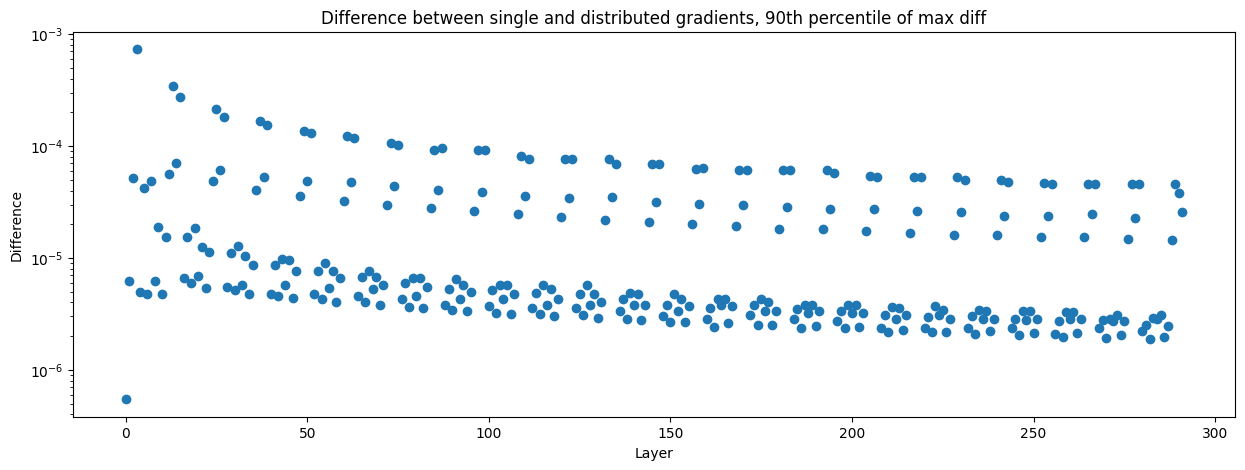

In [19]:
import matplotlib.pyplot as plt
# wider canvas
plt.rcParams.update({'figure.figsize': (15,5)})
plt.plot(range(len(diff_by_layer_95_correct)), diff_by_layer_95_correct.values(), 'o')
plt.xlabel('Layer')
plt.ylabel('Difference')
plt.title('Difference between single and distributed gradients, 90th percentile of max diff')
plt.yscale('log')

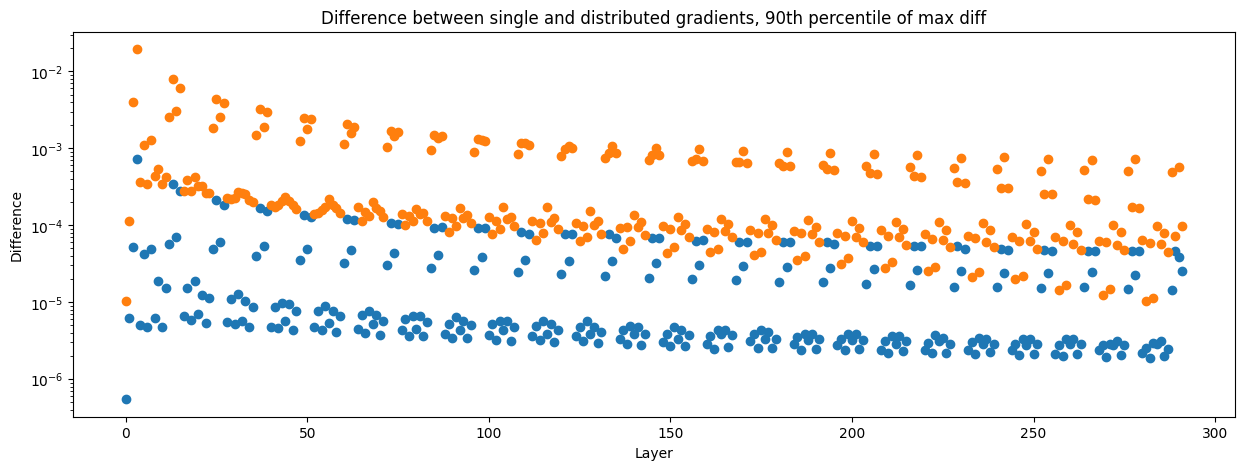

In [36]:
import matplotlib.pyplot as plt
# wider canvas
plt.rcParams.update({'figure.figsize': (15,5)})
plt.plot(range(len(diff_by_layer_95_correct)), diff_by_layer_95_correct.values(), 'o')
plt.plot(range(len(diff_by_layer_95_bug)), diff_by_layer_95_bug.values(), 'o')
plt.xlabel('Layer')
plt.ylabel('Difference')
plt.title('Difference between single and distributed gradients, 90th percentile of max diff')
plt.yscale('log')

In [45]:
len(diff_by_layer_95_correct), , len(diff_by_layer)

(292, 0, 292)

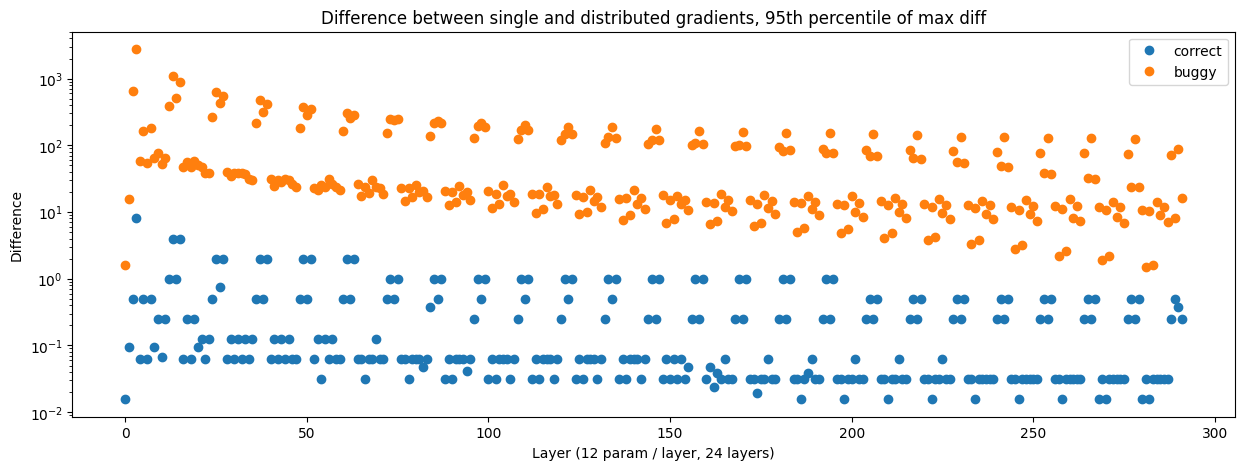

In [75]:
import matplotlib.pyplot as plt
# wider canvas
plt.rcParams.update({'figure.figsize': (15,5)})
plt.plot(range(len(diff_by_layer)), diff_by_layer_95_correct.values(), 'o')
plt.plot(range(len(diff_by_layer)), diff_by_layer_95_bug.values(), 'o')
plt.xlabel('Layer (12 param / layer, 24 layers)')
plt.ylabel('Difference')
plt.title('Difference between single and distributed gradients, 95th percentile of max diff')
plt.yscale('log')
plt.legend(['correct', 'buggy', ])

In [159]:
for k in single_dict.keys():
    print(f"{k[14:]:60}", f"{str(list(single_dict[k].shape)):15}", f"{str(list(distri_dict_1[k].shape)):15}", f"{str(list(distri_dict_2[k].shape)):15}",)

embedding.word_embeddings.weight                             [50304, 1024]   [25216, 1024]   [25216, 1024]  
embedding.position_embeddings.weight                         [1024, 1024]    [1024, 1024]    [1024, 1024]   
decoder.layers.0.self_attention.linear_proj.weight           [1024, 1024]    [1024, 512]     [1024, 512]    
decoder.layers.0.self_attention.linear_proj.bias             [1024]          [1024]          [1024]         
decoder.layers.0.self_attention.linear_qkv.layer_norm_weight [1024]          [1024]          [1024]         
decoder.layers.0.self_attention.linear_qkv.layer_norm_bias   [1024]          [1024]          [1024]         
decoder.layers.0.self_attention.linear_qkv.weight            [3072, 1024]    [1536, 1024]    [1536, 1024]   
decoder.layers.0.self_attention.linear_qkv.bias              [3072]          [1536]          [1536]         
decoder.layers.0.mlp.linear_fc1.layer_norm_weight            [1024]          [1024]          [1024]         
decoder.layers.0.ml

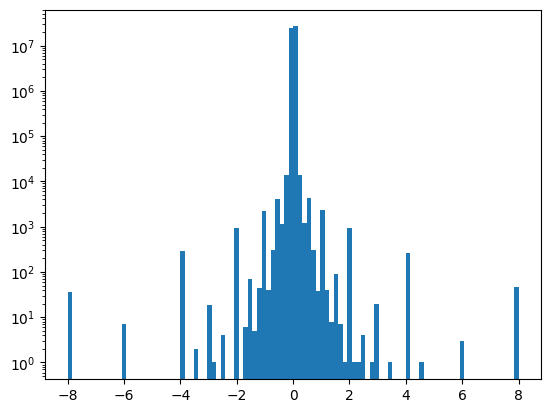

In [28]:
import matplotlib.pyplot as plt
plt.hist((sing_embed - dist_embed).view(-1).numpy(), bins=100)
plt.yscale('log')

In [24]:
sing_embed = single_dict['module.module.embedding.word_embeddings.weight']
dist_embed = torch.concat((distri_dict_1['module.module.embedding.word_embeddings.weight'], distri_dict_2['module.module.embedding.word_embeddings.weight'][:25088, :]), dim=0)

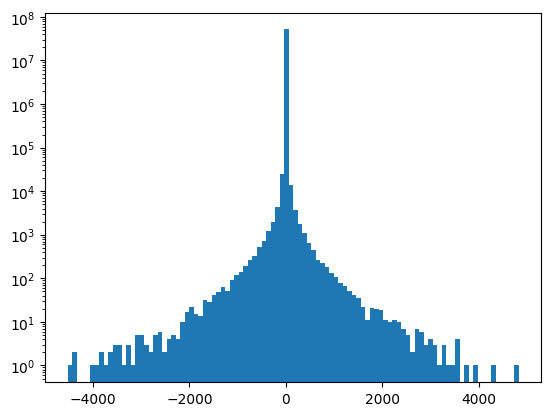

In [25]:
import matplotlib.pyplot as plt
plt.hist((sing_embed - dist_embed).view(-1).numpy(), bins=100)
plt.yscale('log')

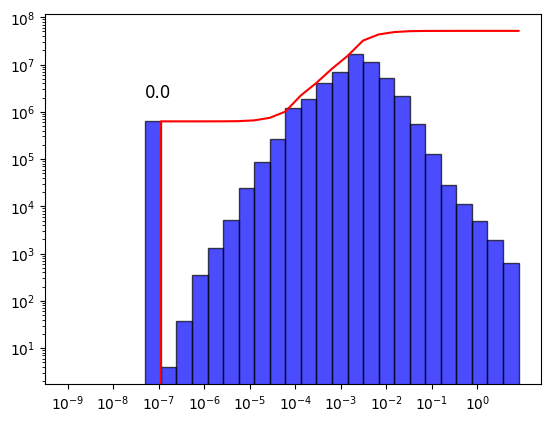

In [116]:
import numpy as np
arr = diff.abs().view(-1).numpy()
bins = np.logspace(np.log10(arr.min()+1e-9), np.log10(arr.max()), 30)
plt.hist(arr+1e-7, bins=bins, alpha=0.7, color='blue', edgecolor='black', histtype='bar')
plt.yscale('log')
plt.xscale('log')
x_ticks = [10**i for i in range(int(np.log10(max(1e-9, arr.min()))), int(np.log10(arr.max())) + 1)]
plt.xticks(x_ticks, [f'$10^{{{i}}}$' for i in range(int(np.log10(max(1e-9, arr.min()))), int(np.log10(arr.max())) + 1)])

counts, bin_edges = np.histogram(arr+1e-7, bins=bins)
cdf = np.cumsum(counts)
plt.plot(bin_edges[1:], cdf, 'r-', label='CDF')

plt.text(5e-8, 2e6, "0.0", fontsize=12, color='black')
plt.show()

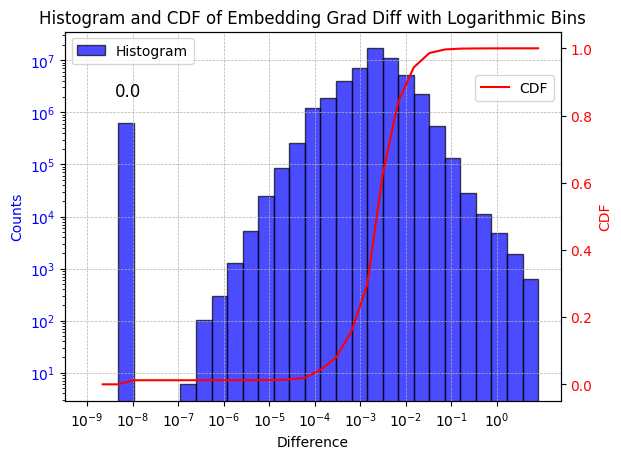

In [139]:
import numpy as np
import matplotlib.pyplot as plt
arr = diff.abs().view(-1).numpy()
bins = np.logspace(np.log10(arr.min()+1e-9), np.log10(arr.max()), 30)
fig, ax1 = plt.subplots()
counts, bin_edges, patches = ax1.hist(arr+1e-8, bins=bins, alpha=0.7, color='blue', edgecolor='black', histtype='bar', label='Histogram')
ax1.set_xscale('log')
ax1.set_yscale('log')
x_ticks = [10**i for i in range(int(np.log10(max(1e-9, arr.min()))), int(np.log10(arr.max())) + 1)]
ax1.set_xticks(x_ticks)
ax1.set_xticklabels([f'$10^{{{i}}}$' for i in range(int(np.log10(max(1e-9, arr.min()))), int(np.log10(arr.max())) + 1)])
ax1.legend(loc='upper left')
ax1.set_title('Histogram and CDF of Embedding Grad Diff with Logarithmic Bins')
ax1.set_xlabel('Difference')
ax1.set_ylabel('Counts', color='blue')
ax1.tick_params(axis='y', labelcolor='blue')
ax1.text(4e-9, 2e6, "0.0", fontsize=12, color='black')

ax2 = ax1.twinx()
cdf = np.cumsum(counts)
cdf /= cdf[-1]
ax2.plot(bin_edges[1:], cdf, 'r-', label='CDF')
ax2.set_ylabel('CDF', color='red')
ax2.tick_params(axis='y', labelcolor='red')

ax2.legend(loc='upper right', bbox_to_anchor=(1, 0.9))
# 显示网格
ax1.grid(True, which='major', linestyle='--', linewidth=0.5)
plt.show()

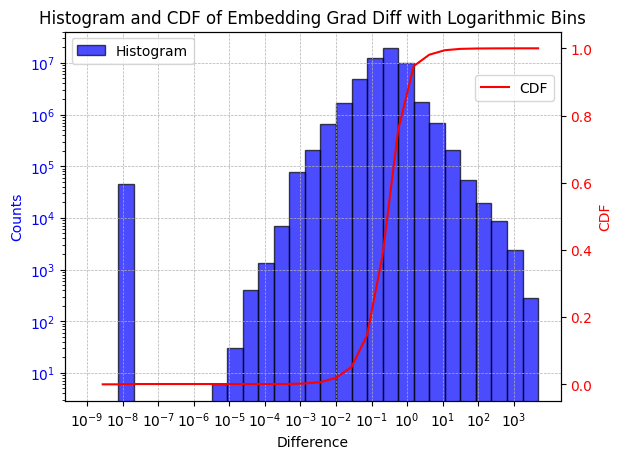

In [26]:
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.figsize': (6.4,4.8)})
diff = sing_embed - dist_embed
arr = diff.abs().view(-1).numpy()
bins = np.logspace(np.log10(arr.min()+1e-9), np.log10(arr.max()), 30)
fig, ax1 = plt.subplots()
counts, bin_edges, patches = ax1.hist(arr+1e-8, bins=bins, alpha=0.7, color='blue', edgecolor='black', histtype='bar', label='Histogram')
ax1.set_xscale('log')
ax1.set_yscale('log')
x_ticks = [10**i for i in range(int(np.log10(max(1e-9, arr.min()))), int(np.log10(arr.max())) + 1)]
ax1.set_xticks(x_ticks)
ax1.set_xticklabels([f'$10^{{{i}}}$' for i in range(int(np.log10(max(1e-9, arr.min()))), int(np.log10(arr.max())) + 1)])
ax1.legend(loc='upper left')
ax1.set_title('Histogram and CDF of Embedding Grad Diff with Logarithmic Bins')
ax1.set_xlabel('Difference')
ax1.set_ylabel('Counts', color='blue')
ax1.tick_params(axis='y', labelcolor='blue')
# ax1.text(4e-9, 2e6, "0.0", fontsize=12, color='black')

ax2 = ax1.twinx()
cdf = np.cumsum(counts)
cdf /= cdf[-1]
ax2.plot(bin_edges[1:], cdf, 'r-', label='CDF')
ax2.set_ylabel('CDF', color='red')
ax2.tick_params(axis='y', labelcolor='red')

ax2.legend(loc='upper right', bbox_to_anchor=(1, 0.9))
# 显示网格
ax1.grid(True, which='major', linestyle='--', linewidth=0.5)
plt.show()